# Recovery: monthly payment schedules

Our finance utilities calculate monthly payment proposals and their implied rates. This notebook imports all calculations from `finance_utils.py` and presents their use, validation results and amortization charts.

**PayPal Invoicing integration is pending.** The module and output contract remain subject to the changes required by that integration. These results are internal proposals, not PayPal API payloads or executed agreements.

## Scope and dependencies

The module uses `numpy` and `numpy-financial`; this notebook adds `pandas`, `matplotlib` and Jupyter for presentation.

Our current scope covers fixed-rate monthly annuities, contractual payment dates, principal and interest breakdowns, outstanding balances and implied rates for variable monthly cash flows. Actual-day accrual, fees, taxes, prepayments, late-payment handling and PayPal execution are outside this version.

Notebook environment setup:

```bash
python -m pip install numpy numpy-financial pandas matplotlib ipykernel
```

The notebook and `finance_utils.py` share the repository root.

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from finance_utils import (
    build_dated_schedule,
    build_mthly_schedule,
    evaluate_cash_flows,
    monthly_due_dates,
)

## Inputs and contractual conventions

`build_dated_schedule(principal, annual_rate, n, pivot_date)` combines the financial schedule and payment dates through the shared validator.

| Input | Current rule |
|---|---|
| `principal` | Positive finite initial balance. |
| `annual_rate` | Nominal annual decimal rate: `0.16` means 16%; accepted range is `0 <= rate < 3`. |
| `n` | Integer from 1 through 60. |
| `pivot_date` | ISO date `YYYY-MM-DD` for the complete schedule. The validator also accepts Unix seconds, but normalization before date generation remains pending. |

The monthly rate is the nominal annual rate divided by 12. This is not an effective-annual conversion. Each period is a contractual month; its number of calendar days does not change the rate.

The financial schedule and date list contain **n + 1 movements**. Period 0 is the pivot with the initial balance and no payment. The first payment follows one contractual month later. All amounts share one currency and are presented with two decimal places.

## Example: 12 monthly payments

The pivot is January 31, 2027, making February 28 the first payment date. This example uses a USD 900 balance and a 30% nominal annual rate (2.5% monthly). The module itself does not attach or validate a currency.

In [2]:
principal = 900.00
annual_rate = 0.30  # 30% nominal annual interest rate, equivalent to 2.5% monthly interest rate
n = 12
pivot_date = "2027-01-31"

schedule = build_dated_schedule(principal, annual_rate, n, pivot_date)
payment_table = pd.DataFrame.from_dict(schedule, orient="index")
payment_table.index.name = "period"
payment_table = payment_table[["due_date", "payment", "interest", "principal_paid", "balance"]]
display(
    payment_table.style.format(
        {name: "{:,.2f}" for name in ["payment", "interest", "principal_paid", "balance"]}
    )
)

,due_date,payment,interest,principal_paid,balance
period,,,,,
0,2027-01-31,0.00,0.00,0.00,900.00
1,2027-02-28,87.74,22.50,65.24,834.76
2,2027-03-31,87.74,20.87,66.87,767.89
3,2027-04-30,87.74,19.20,68.54,699.35
4,2027-05-31,87.74,17.48,70.25,629.10
5,2027-06-30,87.74,15.73,72.01,557.09
6,2027-07-31,87.74,13.93,73.81,483.27
7,2027-08-31,87.74,12.08,75.66,407.62
8,2027-09-30,87.74,10.19,77.55,330.07


## Payment composition and outstanding balance

Each stacked bar is the sum of the **returned, rounded** principal and interest amounts. The dashed line shows the returned regular payment, so any cent differences remain observable. Period 0 is included on the x-axis as the pivot: it has no payment bar. Dates are monthly categories, not an elapsed-day scale.

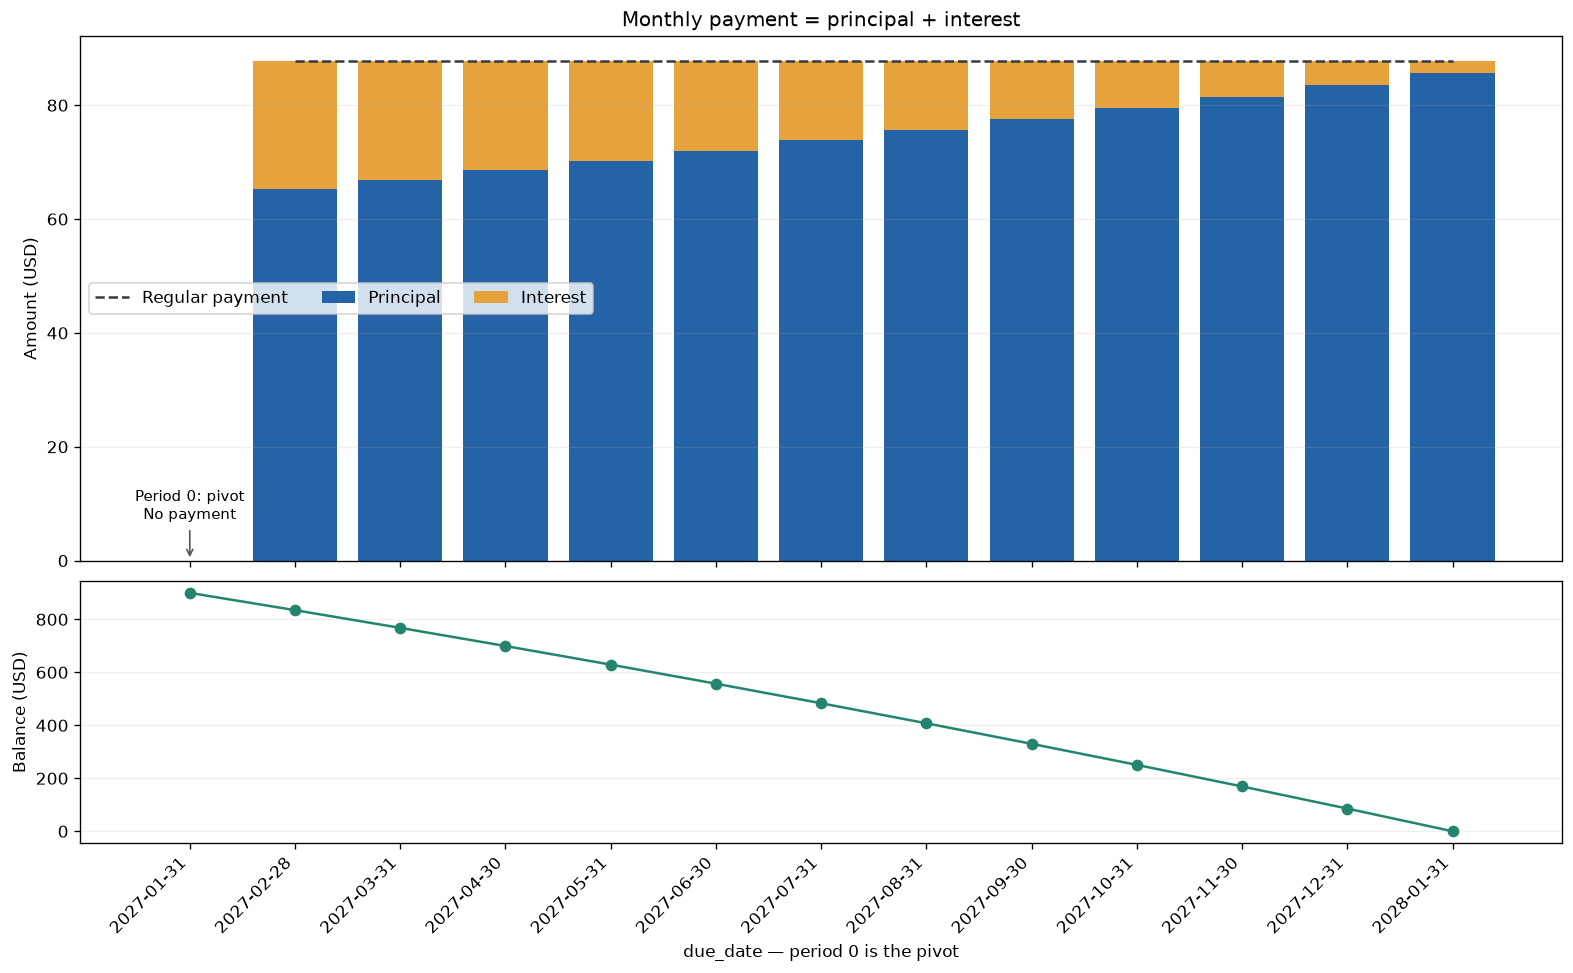

In [3]:
x = np.arange(len(payment_table))
labels = payment_table["due_date"].tolist()
fig, (ax, balance_ax) = plt.subplots(
    2,
    1,
    figsize=(13, 8),
    sharex=True,
    gridspec_kw={"height_ratios": [2, 1]},
    constrained_layout=True,
)
ax.bar(x, payment_table["principal_paid"], label="Principal", color="#2463A6")
ax.bar(
    x,
    payment_table["interest"],
    bottom=payment_table["principal_paid"],
    label="Interest",
    color="#E6A23C",
)
ax.plot(
    x[1:],
    payment_table["payment"].iloc[1:],
    linestyle="--",
    color="#343A40",
    label="Regular payment",
    linewidth=1.5,
)
ax.set(title="Monthly payment = principal + interest", ylabel="Amount (USD)")
ax.annotate(
    "Period 0: pivot\nNo payment",
    xy=(0, 0),
    xytext=(0, 25),
    textcoords="offset points",
    ha="center",
    fontsize=9,
    arrowprops={"arrowstyle": "->", "color": "#555555"},
)
ax.legend(ncols=3)
ax.grid(axis="y", alpha=0.2)
balance_ax.plot(x, payment_table["balance"], marker="o", color="#23856D")
balance_ax.set(ylabel="Balance (USD)", xlabel="due_date — period 0 is the pivot")
balance_ax.set_xticks(x, labels, rotation=45, ha="right")
balance_ax.grid(axis="y", alpha=0.2)
fig.savefig("finance_utils_amortization.png", dpi=160, bbox_inches="tight")
plt.show()

## Date rules: preserve the original anchor

`monthly_due_dates` compares the pivot day with the last day of its month. If they match, **all following dates are month-end dates**. Otherwise, it preserves the original day, clipping only when that day does not exist. Dates are always derived from the pivot, so February never permanently shifts the anchor.

There is no boolean parameter. Consequently, a February 28 pivot in a non-leap year implies month end, not a fixed day 28. Weekends and holidays are not adjusted.

In [4]:
date_examples = {
    "Month end, non-leap year": monthly_due_dates("2027-01-31", 3),
    "Month end, leap year": monthly_due_dates("2028-01-31", 3),
    "Fixed day 30": monthly_due_dates("2027-01-30", 3),
    "Fixed day 15": monthly_due_dates("2027-01-15", 3),
    "February pivot implies month end": monthly_due_dates("2027-02-28", 3),
}
display(pd.DataFrame(date_examples).rename_axis("period"))
assert date_examples["Fixed day 30"][:3] == ["2027-01-30", "2027-02-28", "2027-03-30"]
assert date_examples["Month end, leap year"][1] == "2028-02-29"

,"Month end, non-leap year","Month end, leap year",Fixed day 30,Fixed day 15,February pivot implies month end
period,,,,,
0,2027-01-31,2028-01-31,2027-01-30,2027-01-15,2027-02-28
1,2027-02-28,2028-02-29,2027-02-28,2027-02-15,2027-03-31
2,2027-03-31,2028-03-31,2027-03-30,2027-03-15,2027-04-30
3,2027-04-30,2028-04-30,2027-04-30,2027-04-15,2027-05-31


## Separate responsibilities and JSON serialization

The wrapper first calls `build_mthly_schedule` and `monthly_due_dates` independently, then inserts each matching date into the financial dictionary. Integer keys are converted to strings when serialized as JSON.

In [5]:
financial_movements = build_mthly_schedule(principal, annual_rate / 12, n)
due_dates = monthly_due_dates(pivot_date, n)
assert len(financial_movements) == len(due_dates) == len(schedule) == n + 1
assert schedule[0]["due_date"] == pivot_date
assert schedule[0]["payment"] == 0
assert all(schedule[k]["due_date"] == due_dates[k] for k in range(n + 1))
serialized = json.dumps(schedule, indent=2, allow_nan=False)
print(json.dumps({k: schedule[k] for k in range(3)}, indent=2))

{
  "0": {
    "payment": 0.0,
    "interest": 0.0,
    "principal_paid": 0.0,
    "balance": 900.0,
    "due_date": "2027-01-31"
  },
  "1": {
    "payment": 87.74,
    "interest": 22.5,
    "principal_paid": 65.24,
    "balance": 834.76,
    "due_date": "2027-02-28"
  },
  "2": {
    "payment": 87.74,
    "interest": 20.87,
    "principal_paid": 66.87,
    "balance": 767.89,
    "due_date": "2027-03-31"
  }
}


## Shared validation

Invalid inputs produce a console message and an empty dictionary `{}` from the wrapper. The boolean returned by `validate_variables` controls that flow without stopping the demonstration.

In [6]:
invalid_inputs = [
    ("Negative rate", {"annual_rate": -0.01}),
    ("Rate at upper limit", {"annual_rate": 3.0}),
    ("Non-integer payment count", {"n": 12.0}),
    ("Payment count above limit", {"n": 61}),
    ("Invalid calendar date", {"pivot_date": "2027-02-30"}),
]
validation_results = []
for case, override in invalid_inputs:
    params = dict(principal=principal, annual_rate=annual_rate, n=n, pivot_date=pivot_date)
    params.update(override)
    result = build_dated_schedule(**params)
    assert result == {}
    validation_results.append({"case": case, "result": str(result)})
display(pd.DataFrame(validation_results))

Validation error: annual_rate must be between 0 and 3 (exclusive)
Validation error: annual_rate must be between 0 and 3 (exclusive)
Validation error: n must be an integer between 1 and 60
Validation error: n must be an integer between 1 and 60
Validation error: day is out of range for month


,case,result
0,Negative rate,{}
1,Rate at upper limit,{}
2,Non-integer payment count,{}
3,Payment count above limit,{}
4,Invalid calendar date,{}


## Rounding and remaining integration work

Calculations use floating point. Payment, principal, interest and balance are independently rounded to two decimals. Final-payment reconciliation is pending; cent-level equality is not guaranteed for every row or for total principal repayments. The diagnostics below quantify these differences.

The current `balance` field represents outstanding balance. Final field names and monetary reconciliation remain subject to integration changes. The calculation does not establish permission to collect additional finance charges.

In [7]:
diagnostics = pd.Series(
    {
        "Maximum absolute payment minus principal minus interest": (
            payment_table["payment"] - payment_table["principal_paid"] - payment_table["interest"]
        )
        .abs()
        .max(),
        "Sum of principal repayments minus initial principal": payment_table["principal_paid"].sum()
        - principal,
        "Returned final outstanding balance": payment_table["balance"].iloc[-1],
    }
).round(2)
display(diagnostics.to_frame("amount"))

,amount
Maximum absolute payment minus principal minus interest,0.01
Sum of principal repayments minus initial principal,0.00
Returned final outstanding balance,-0.00


## Inverse calculation: monthly IRR

`evaluate_cash_flows(cash_flows)` uses `numpy_financial.irr` and returns `monthly_rate`, `effective_annual_rate` and `annual_nominal_rate`, rounded to five decimal places.

The first flow is the negative initial balance. Subsequent flows occupy monthly slots and may differ or be negative; zero represents a month with no movement. The shared validator requires their net sum to cover the initial principal. Multiple changes of sign can produce multiple IRRs.

Rates are decimal fractions: `0.01` represents 1%. Dates are not part of this calculation; monthly periods follow the same contractual convention as the forward schedule. Invalid input returns `{}` with a console message.

In [8]:
cash_flows = [-10000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 950]
rates = evaluate_cash_flows(cash_flows)
print(json.dumps(rates, indent=2))
recovered_rates = evaluate_cash_flows(
    [-principal] + [schedule[k]["payment"] for k in range(1, n + 1)]
)
assert abs(recovered_rates["monthly_rate"] - annual_rate / 12) < 1e-5

{
  "monthly_rate": 0.02863,
  "effective_annual_rate": 0.40324,
  "annual_nominal_rate": 0.34361
}


## Hackathon demonstration cases

These six calls exercise valid schedules, implied-rate calculation and validation failures without an executable entry point in the utilities module.

In [9]:
import json

### 16% nominal annual, 12 payments

The schedule contains 13 movements, including the January 31, 2024 pivot and the February 29 first payment.

In [10]:
print(json.dumps(build_dated_schedule(10000, 0.16, 12, "2024-01-31"), indent=2))

{
  "0": {
    "payment": 0.0,
    "interest": 0.0,
    "principal_paid": 0.0,
    "balance": 10000.0,
    "due_date": "2024-01-31"
  },
  "1": {
    "payment": 907.31,
    "interest": 133.33,
    "principal_paid": 773.98,
    "balance": 9226.02,
    "due_date": "2024-02-29"
  },
  "2": {
    "payment": 907.31,
    "interest": 123.01,
    "principal_paid": 784.29,
    "balance": 8441.73,
    "due_date": "2024-03-31"
  },
  "3": {
    "payment": 907.31,
    "interest": 112.56,
    "principal_paid": 794.75,
    "balance": 7646.98,
    "due_date": "2024-04-30"
  },
  "4": {
    "payment": 907.31,
    "interest": 101.96,
    "principal_paid": 805.35,
    "balance": 6841.63,
    "due_date": "2024-05-31"
  },
  "5": {
    "payment": 907.31,
    "interest": 91.22,
    "principal_paid": 816.09,
    "balance": 6025.54,
    "due_date": "2024-06-30"
  },
  "6": {
    "payment": 907.31,
    "interest": 80.34,
    "principal_paid": 826.97,
    "balance": 5198.57,
    "due_date": "2024-07-31"
  },
 

### Variable final payment

Eleven payments of 1,000 and a final payment of 950 cover the initial balance. The output contains the implied monthly and annual rates.

In [11]:
print(evaluate_cash_flows([-10000] + [1000] * 11 + [950]))

{'monthly_rate': 0.02863, 'effective_annual_rate': 0.40324, 'annual_nominal_rate': 0.34361}


### Insufficient net receipts

Five payments of 1,000 plus 950 total 5,950. Validation rejects the proposal, prints the reason and returns {}.

In [12]:
print(evaluate_cash_flows([-10000] + [1000] * 5 + [950]))

Validation error: The net subsequent cash flows must cover the initial principal
{}


### 255% nominal annual

The rate 2.55 is below the current upper limit of 3. The schedule is accepted; this technical limit does not imply permission to charge that rate.

In [13]:
print(json.dumps(build_dated_schedule(10000, 2.55, 12, "2026-01-31"), indent=2))

{
  "0": {
    "payment": 0.0,
    "interest": 0.0,
    "principal_paid": 0.0,
    "balance": 10000.0,
    "due_date": "2026-01-31"
  },
  "1": {
    "payment": 2358.6,
    "interest": 2125.0,
    "principal_paid": 233.6,
    "balance": 9766.4,
    "due_date": "2026-02-28"
  },
  "2": {
    "payment": 2358.6,
    "interest": 2075.36,
    "principal_paid": 283.24,
    "balance": 9483.16,
    "due_date": "2026-03-31"
  },
  "3": {
    "payment": 2358.6,
    "interest": 2015.17,
    "principal_paid": 343.43,
    "balance": 9139.73,
    "due_date": "2026-04-30"
  },
  "4": {
    "payment": 2358.6,
    "interest": 1942.19,
    "principal_paid": 416.41,
    "balance": 8723.32,
    "due_date": "2026-05-31"
  },
  "5": {
    "payment": 2358.6,
    "interest": 1853.71,
    "principal_paid": 504.89,
    "balance": 8218.43,
    "due_date": "2026-06-30"
  },
  "6": {
    "payment": 2358.6,
    "interest": 1746.42,
    "principal_paid": 612.18,
    "balance": 7606.24,
    "due_date": "2026-07-31"
 

### 355% nominal annual

The rate 3.55 exceeds the accepted range. Validation prints the reason and the wrapper returns {}.

In [14]:
print(json.dumps(build_dated_schedule(10000, 3.55, 12, "2026-01-31"), indent=2))

Validation error: annual_rate must be between 0 and 3 (exclusive)
{}


### Negative payment count

The count -2 is outside 1 through 60. Validation prints the reason and the wrapper returns {}.

In [15]:
print(json.dumps(build_dated_schedule(10000, 2.55, -2, "2026-01-31"), indent=2))

Validation error: n must be an integer between 1 and 60
{}


## PayPal Invoicing integration

Our contribution currently calculates and compares proposals before merchant approval. **PayPal Invoicing integration is pending**, including invoice retrieval, API mapping, approval, persistence, payment execution and reconciliation.

The schedule is an internal JSON-compatible dictionary. Sandbox verification of the collection mechanism remains pending. Both the module and notebook are subject to the changes required by this integration.

Reference: [PayPal invoice object](https://developer.paypal.com/invoicing/object/).